#### Ridge Regression <br>
##### Loss function=OLS function + a*sum of ai**2

In [1]:
import pandas as pd
import numpy as np
diabetes_df=pd.read_csv(r"C:\Users\user\Downloads\diabetes_prediction_dataset.csv\diabetes_prediction_dataset.csv")
import pandas as pd
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

diabetes_df["gender"] = le.fit_transform(diabetes_df["gender"])#label encoding

diabetes_df = pd.get_dummies(
    diabetes_df,
    columns=["smoking_history"],
    dtype=int
)#one_hot encoding

In [2]:
X=diabetes_df.drop(["blood_glucose_level"],axis=1).values
y=diabetes_df["blood_glucose_level"].values

In [3]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
X_train,X_test, y_train , y_test=train_test_split(X,y ,random_state=24,test_size=0.3)
score=[]
for alpha in [0.1, 1.0, 10.0, 100.0, 1000.0]: 
    ridge=Ridge(alpha=alpha)
    ridge.fit(X_train, y_train) 
    score.append(ridge.score(X_test, y_test))
y_pred = ridge.predict(X_test) 
 
print(score)


[0.1767690369188719, 0.17676880079339208, 0.1767657605961389, 0.1766707928599992, 0.171627338360276]


In [4]:
from sklearn.linear_model import Lasso 
scores = [] 
for alpha in [0.01, 1.0, 10.0, 20.0, 50.0]: 
    lasso = Lasso(alpha=alpha) 
    lasso.fit(X_train, y_train) 
    lasso_pred = lasso.predict(X_test) 
    scores.append(lasso.score(X_test, y_test)) 
print(scores)

[0.17681598389998532, 0.16784256416057486, 0.01372043570374104, 0.011387919801799984, 0.009051758183378]


#### Lasso for feature selection in scikit-learn

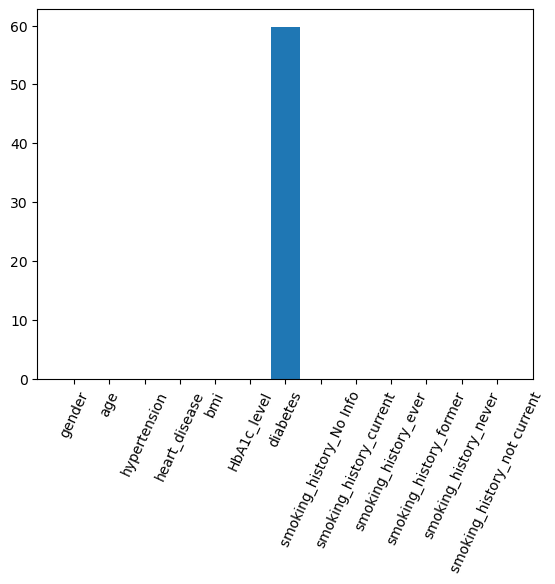

In [9]:
from sklearn.linear_model import Lasso 
import matplotlib.pyplot as plt
X=diabetes_df.drop(["blood_glucose_level"],axis=1).values
y=diabetes_df["blood_glucose_level"].values
names = diabetes_df.drop("blood_glucose_level", axis=1).columns 
lasso = Lasso(alpha=0.1) 
lasso_coef = lasso.fit(X, y).coef_ 
plt.bar(names, lasso_coef) 
plt.xticks(rotation=65) 
plt.show() 